# 03 — How Much Is the Driver?

Notebook 01 decided what to measure: each driver's best Q1 lap, as a percentage gap to the fastest
lap of that session. Notebook 02 fitted the model that splits that gap into a driver part, a car part
and a season part.

This one answers the question the project was built around — and, just as importantly, works out how
far the answer can be trusted.

**Contents:**
1. Loading the fitted model.
2. Variance decomposition — driver vs car vs everything else.
3. Putting the answer in lap-time terms.
4. Driver ratings.
5. What drives the uncertainty.
6. Car ratings.
7. Where the method strains.
8. Quantified takeaways.

## Loading the fitted model

The posterior from notebook 02 is loaded rather than refitted — sampling takes minutes, and refitting
in a second notebook invites drift between the two.

What comes back is 8,000 draws (4 chains × 2,000) for every parameter: one overall intercept, one
effect per driver, per constructor-season and per season, and the standard deviations that govern
each of those groups.

In [1]:
!pip install -q arviz

import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt
import glob

pd.set_option('display.max_columns', None)

idata = az.from_netcdf(glob.glob('/kaggle/input/**/model_sqrt.nc', recursive=True)[0])
model_data = pd.read_csv(glob.glob('/kaggle/input/**/model_data.csv', recursive=True)[0])

print(model_data.shape)
print(list(idata.posterior.data_vars))

(3008, 11)
['sigma', 'Intercept', '1|drv_sigma', '1|team_season_sigma', '1|season_sigma', '1|drv', '1|team_season', '1|season']


In [2]:
# what does the posterior actually contain, and how is it indexed?
for name in idata.posterior.data_vars:
    var = idata.posterior[name]
    print(f'{name:24s} dims={var.dims}  shape={var.shape}')

sigma                    dims=('chain', 'draw')  shape=(4, 2000)
Intercept                dims=('chain', 'draw')  shape=(4, 2000)
1|drv_sigma              dims=('chain', 'draw')  shape=(4, 2000)
1|team_season_sigma      dims=('chain', 'draw')  shape=(4, 2000)
1|season_sigma           dims=('chain', 'draw')  shape=(4, 2000)
1|drv                    dims=('chain', 'draw', 'drv__factor_dim')  shape=(4, 2000, 43)
1|team_season            dims=('chain', 'draw', 'team_season__factor_dim')  shape=(4, 2000, 81)
1|season                 dims=('chain', 'draw', 'season__factor_dim')  shape=(4, 2000, 8)


43 drivers, 81 constructor-seasons, 8 seasons — and every effect carries its full set of draws rather
than a single fitted value. That's what makes it possible to put an interval on everything below.

In [3]:
print('coords:')
for name, values in idata.posterior.coords.items():
    print(f'  {name:24s} n={len(values):4d}  e.g. {list(values.values[:3])}')

coords:
  chain                    n=   4  e.g. [np.int64(0), np.int64(1), np.int64(2)]
  draw                     n=2000  e.g. [np.int64(0), np.int64(1), np.int64(2)]
  drv__factor_dim          n=  43  e.g. [np.str_('AIT'), np.str_('ALB'), np.str_('ALO')]
  team_season__factor_dim  n=  81  e.g. [np.str_('Alfa Romeo 2022'), np.str_('Alfa Romeo 2023'), np.str_('Alfa Romeo Racing 2019')]
  season__factor_dim       n=   8  e.g. [np.str_('2018'), np.str_('2019'), np.str_('2020')]


## Variance decomposition

The model estimates one standard deviation per grouping: how much drivers differ from each other, how
much cars differ, how much seasons differ, and how much is left over. Squaring those gives variances,
and variances add up — so each one's share of the total is the share of qualifying pace variation it
accounts for.

One detail matters for doing this honestly. **The shares get computed inside each posterior draw, not
from the averaged standard deviations.** Every draw is one coherent story about the world, so taking
the ratio within a draw and summarising afterwards keeps the uncertainty intact. Averaging first and
dividing once would collapse it into a single confident-looking number with no interval — the false
precision this project set out to avoid.

These shares sit on the square-root scale the model was fitted on. The ordering is unaffected, but
they aren't directly percentages of lap time; the next section deals with that.

In [4]:
posterior = idata.posterior

variances = {
    'car': posterior['1|team_season_sigma'].values.flatten() ** 2,
    'driver': posterior['1|drv_sigma'].values.flatten() ** 2,
    'season': posterior['1|season_sigma'].values.flatten() ** 2,
    'unexplained': posterior['sigma'].values.flatten() ** 2,
}

total = sum(variances.values())
shares = pd.DataFrame({name: values / total for name, values in variances.items()})

summary = shares.quantile([.055, .5, .945]).T
summary.columns = ['lower_89', 'median', 'upper_89']
(summary * 100).round(1)

,lower_89,median,upper_89
car,24.3,31.4,39.5
driver,6.9,11.0,17.2
season,0.1,3.1,14.4
unexplained,45.2,52.6,58.6


In [5]:
# of the variation the model can attribute, how is it split?
explained = shares[['car', 'driver', 'season']]
explained = explained.div(explained.sum(axis=1), axis=0)

print('share of *explained* variation:')
print((explained.quantile([.055, .5, .945]).T
       .set_axis(['lower_89', 'median', 'upper_89'], axis=1) * 100).round(1))
print()
print('car : driver ratio  ->',
      f'{(shares["car"] / shares["driver"]).median():.2f}x',
      f'[{(shares["car"] / shares["driver"]).quantile(.055):.2f},',
      f'{(shares["car"] / shares["driver"]).quantile(.945):.2f}]')

share of *explained* variation:
        lower_89  median  upper_89
car         49.5    67.3      80.7
driver      14.0    23.4      35.9
season       0.2     6.7      27.9

car : driver ratio  -> 2.84x [1.57, 5.27]


### The answer

| | share of all variation | share of what the model explains |
|---|---|---|
| **car** | 31.4% [24.3, 39.5] | **67.3%** [49.5, 80.7] |
| **driver** | 11.0% [6.9, 17.2] | **23.4%** [14.0, 35.9] |
| season | 3.1% [0.1, 14.4] | 6.7% [0.2, 27.9] |
| unexplained | **52.6%** [45.2, 58.6] | — |

**The car counts for roughly 2.8× what the driver counts for.** The interval runs from 1.6× to 5.3×,
so the exact multiple is uncertain — but it stays above 1 throughout, meaning the direction isn't in
doubt even at the edges of what the data supports.

Two things deserve as much attention as the headline.

**Over half the variation is unexplained.** Session to session, most of what moves a qualifying lap is
neither the driver nor the car: traffic, a tow, track evolution between runs, a small mistake. That
isn't a failure of the model — it's the reason the estimates pool across 3,008 sessions instead of
being read off any single result, and the reason a one-race judgement of a driver is close to
worthless.

**The season effect is barely identified**, spanning 0.2% to 27.9% of explained variation. Eight
seasons is very little to estimate a spread from, which the weak diagnostics in notebook 02 already
warned about. I'd not quote that number.

## Putting it in lap-time terms

Variance shares on a square-root scale are hard to feel. A more useful question: **how much lap time
separates the best driver from the worst, once they're in the same car?**

Converting needs care, because the square root is non-linear — the same effect is worth more or less
depending on the baseline it's applied to. So rather than a single conversion factor, I evaluate the
model at a realistic operating point: a typical session, an average car, and then swap the driver
from the best in the dataset to the worst.

I report the result in seconds on a 90-second lap, roughly a mid-length circuit.

In [6]:
LAP_SECONDS = 90

intercept = posterior['Intercept'].values.flatten()
driver_draws = posterior['1|drv'].values.reshape(-1, posterior['1|drv'].shape[-1])
car_draws = posterior['1|team_season'].values.reshape(-1, posterior['1|team_season'].shape[-1])

def spread_in_seconds(effect_draws):
    """Best vs worst level, held at a typical session with everything else average."""
    best = effect_draws.min(axis=1)
    worst = effect_draws.max(axis=1)
    gap_best = np.clip(intercept + best, 0, None) ** 2      # sqrt scale -> percent
    gap_worst = np.clip(intercept + worst, 0, None) ** 2
    delta_pct = gap_worst - gap_best
    return delta_pct, delta_pct / 100 * LAP_SECONDS

for label, draws in [('driver', driver_draws), ('car', car_draws)]:
    pct, secs = spread_in_seconds(draws)
    print(f'{label:7s} best vs worst: {np.median(pct):5.2f}% of lap time = '
          f'{np.median(secs):5.2f}s  '
          f'[{np.percentile(secs, 5.5):.2f}, {np.percentile(secs, 94.5):.2f}]')

driver  best vs worst:  1.31% of lap time =  1.18s  [0.94, 1.57]
car     best vs worst:  2.74% of lap time =  2.46s  [2.03, 2.91]


### What that looks like on track

| | best vs worst | on a 90s lap |
|---|---|---|
| **car** | 2.74% of lap time | **2.46s** [2.03, 2.91] |
| **driver** | 1.31% of lap time | **1.18s** [0.94, 1.57] |

Both land where F1 experience says they should. The spread from the quickest car to the slowest is
routinely two to three seconds a lap, and 2.46s sits squarely in that range — a useful check that the
model is describing the sport rather than an artefact.

The driver figure is the interesting one: **swapping the grid's weakest driver for its strongest is
worth about 1.2 seconds a lap, in the same car.** That's a large number in a sport where pole is
often decided by hundredths — and still only about half what the machinery is worth.

## Driver ratings

Each driver gets a full posterior rather than a single number, expressed here in seconds relative to
an average driver on a 90-second lap. Negative is faster.

The width of each interval matters as much as its position. Drivers with few sessions, or who never
left one team, have wide intervals because the data genuinely can't separate them from their car.

In [7]:
driver_names = posterior['1|drv'].coords['drv__factor_dim'].values

def effects_in_seconds(effect_draws):
    """Each level's effect vs an average one, in seconds on a 90s lap."""
    baseline = intercept[:, None] ** 2
    shifted = np.clip(intercept[:, None] + effect_draws, 0, None) ** 2
    return (shifted - baseline) / 100 * LAP_SECONDS

driver_seconds = effects_in_seconds(driver_draws)

ratings = pd.DataFrame({
    'seconds': np.median(driver_seconds, axis=0),
    'lower_89': np.percentile(driver_seconds, 5.5, axis=0),
    'upper_89': np.percentile(driver_seconds, 94.5, axis=0),
}, index=driver_names)

ratings['sessions'] = model_data.groupby('drv').size().reindex(ratings.index)
ratings['teams'] = model_data.groupby('drv')['team'].nunique().reindex(ratings.index)
ratings['width'] = ratings['upper_89'] - ratings['lower_89']

ratings.sort_values('seconds').round(3)

,seconds,lower_89,upper_89,sessions,teams,width
VER,-0.580,-0.699,-0.472,150,1,0.226
LEC,-0.344,-0.467,-0.227,154,2,0.240
HAM,-0.304,-0.431,-0.178,150,2,0.254
NOR,-0.298,-0.433,-0.167,137,1,0.265
SAI,-0.237,-0.363,-0.116,150,4,0.246
PIA,-0.223,-0.391,-0.049,62,1,0.341
RUS,-0.165,-0.295,-0.032,137,2,0.264
ALB,-0.142,-0.270,-0.014,113,3,0.256
ALO,-0.110,-0.241,0.031,121,3,0.272
BOT,-0.100,-0.253,0.054,127,3,0.306


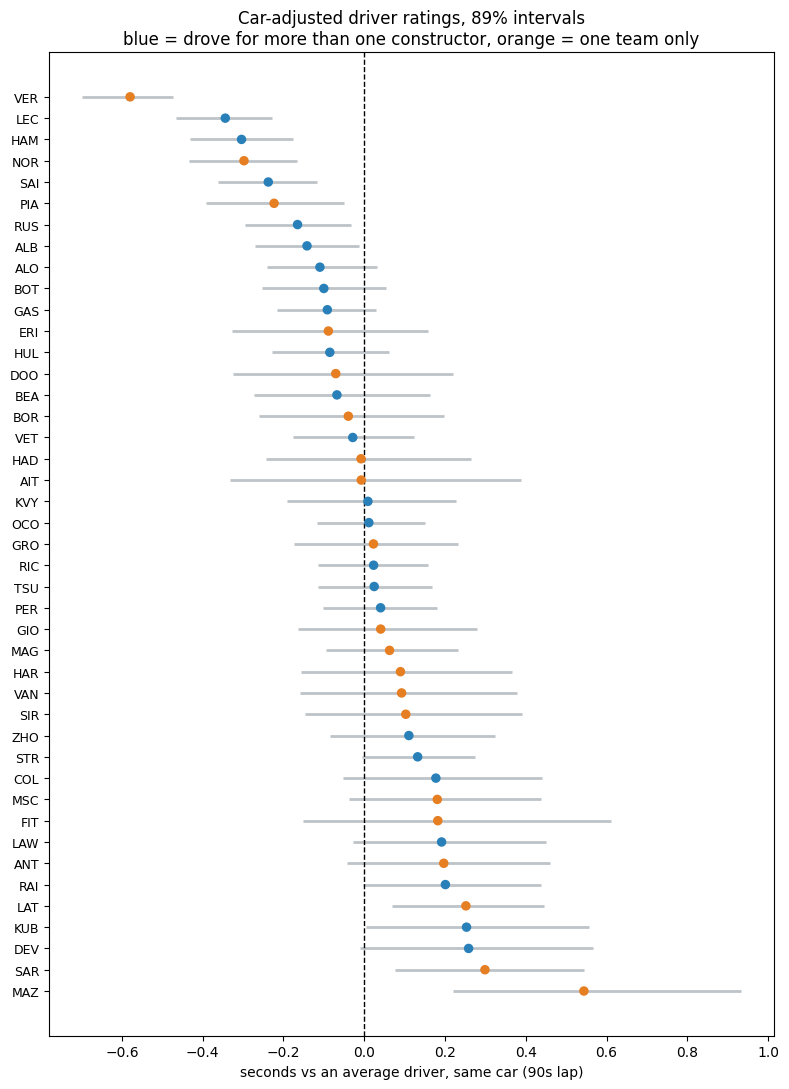

In [8]:
ranked = ratings.sort_values('seconds')
switched = ranked['teams'] > 1

fig, ax = plt.subplots(figsize=(8, 11))
ax.hlines(range(len(ranked)), ranked['lower_89'], ranked['upper_89'],
          color='#bdc3c7', lw=2, zorder=1)
ax.scatter(ranked['seconds'], range(len(ranked)),
           c=np.where(switched, '#2980b9', '#e67e22'), s=34, zorder=3)
ax.axvline(0, color='k', lw=1, ls='--')
ax.set_yticks(range(len(ranked)))
ax.set_yticklabels(ranked.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('seconds vs an average driver, same car (90s lap)')
ax.set_title('Car-adjusted driver ratings, 89% intervals\n'
             'blue = drove for more than one constructor, orange = one team only')
plt.tight_layout()
plt.show()

### What the ranking says

The order lines up with informed opinion about the era, which the model was never told. Verstappen
sits clear at the top by 0.24s over second place; Leclerc, Hamilton and Norris form the next tier. At
the other end sit Mazepin, Sargeant, de Vries and Latifi — the drivers most often named as the
weakest of the period.

That agreement is reassuring rather than impressive on its own: a decomposition that put Mazepin
ahead of Verstappen would be obviously broken, so passing this check is a floor, not a triumph.

**A correction, though.** I claimed earlier that the 20 single-team drivers contribute nothing to
separating driver from car. Verstappen shows that's wrong: `teams = 1`, and he has the *narrowest*
interval on the grid.

The reason is that switching teams isn't the only way to be identified. **Teammates changing within a
team across seasons does the same job.** Verstappen shared Red Bull with Gasly, Albon, Pérez, Lawson
and Tsunoda, all of whom drove elsewhere — so he's tied into the network without ever moving himself.

## What drives the uncertainty

If that's the real mechanism, interval width should track the *amount of comparison available* — how
many sessions, how many distinct teammates — rather than team changes specifically.

In [9]:
teammates = (model_data.merge(model_data, on=['season', 'gp', 'team'])
             .query('drv_x != drv_y')
             .groupby('drv_x')['drv_y'].nunique())

check = ratings.copy()
check['teammates'] = teammates.reindex(check.index).fillna(0)

print('what predicts a narrow interval?')
for col in ['sessions', 'teams', 'teammates']:
    print(f'  correlation(width, {col:10s}) = {check["width"].corr(check[col]):+.2f}')
print()
print('narrowest five:')
print(check.nsmallest(5, 'width')[['seconds', 'width', 'sessions', 'teams', 'teammates']].round(3))
print()
print('widest five:')
print(check.nlargest(5, 'width')[['seconds', 'width', 'sessions', 'teams', 'teammates']].round(3))

what predicts a narrow interval?
  correlation(width, sessions  ) = -0.90
  correlation(width, teams     ) = -0.56
  correlation(width, teammates ) = -0.77

narrowest five:
     seconds  width  sessions  teams  teammates
VER   -0.580  0.226       150      1          6
LEC   -0.344  0.240       154      2          5
GAS   -0.091  0.245       154      4          7
SAI   -0.237  0.246       150      4          4
HAM   -0.304  0.254       150      2          3

widest five:
     seconds  width  sessions  teams  teammates
FIT    0.182  0.760         2      1          1
AIT   -0.007  0.720         1      1          1
MAZ    0.544  0.713        21      1          1
DEV    0.258  0.577        10      2          2
KUB    0.253  0.553        15      2          2


### Precision comes from volume and connection, not from switching teams

| predictor of interval width | correlation |
|---|---|
| sessions | **−0.90** |
| distinct teammates | −0.77 |
| team changes | −0.56 |

The number of sessions dominates, teammate variety comes second, and changing constructor — the thing
I'd assumed was the key — matters least of the three.

Two cases make it concrete. **Verstappen** has 150 sessions and six different teammates without ever
leaving Red Bull, and ends up the most precisely estimated driver in the dataset. **Mazepin** has 21
sessions, a full season's worth, but exactly one teammate and one team, so he stays among the least
precisely estimated.

The honest version of the limitation is therefore narrower than what I wrote in notebook 01. It isn't
that single-team drivers can't be estimated. It's that **drivers with few sessions or few distinct
teammates are weakly connected to the rest of the grid, and their intervals show it.** That's a
better description of the constraint, and it's visible in the chart rather than buried in a caveat.

## Car ratings

The same treatment for constructor-seasons — the side of the decomposition a teammate comparison
could never produce, since teammates share a car by definition.

In [10]:
car_names = posterior['1|team_season'].coords['team_season__factor_dim'].values
car_seconds = effects_in_seconds(car_draws)

cars = pd.DataFrame({
    'seconds': np.median(car_seconds, axis=0),
    'lower_89': np.percentile(car_seconds, 5.5, axis=0),
    'upper_89': np.percentile(car_seconds, 94.5, axis=0),
}, index=car_names).sort_values('seconds')

print('Ten fastest cars, 2018-2025 (seconds vs an average car, 90s lap):')
print(cars.head(10).round(3))
print()
print('Ten slowest:')
print(cars.tail(10).round(3))

Ten fastest cars, 2018-2025 (seconds vs an average car, 90s lap):
                      seconds  lower_89  upper_89
Mercedes 2020          -0.767    -0.910    -0.628
Ferrari 2018           -0.659    -0.813    -0.505
Mercedes 2021          -0.597    -0.751    -0.439
Ferrari 2019           -0.584    -0.745    -0.421
Mercedes 2018          -0.561    -0.727    -0.384
McLaren 2025           -0.538    -0.707    -0.332
Mercedes 2019          -0.516    -0.685    -0.338
Ferrari 2022           -0.487    -0.659    -0.318
Red Bull Racing 2022   -0.438    -0.616    -0.265
Mercedes 2025          -0.431    -0.616    -0.199

Ten slowest:
                        seconds  lower_89  upper_89
Aston Martin 2022         0.432     0.159     0.698
McLaren 2018              0.442     0.151     0.762
Sauber 2018               0.583     0.271     0.911
Haas F1 Team 2020         0.593     0.270     0.933
Alfa Romeo Racing 2020    0.596     0.262     0.967
Williams 2020             0.671     0.348     0.998
Willia

### The cars check out against history

None of this was given to the model, and it lands where the record says it should.

**Mercedes 2020** tops the list — the W11, generally reckoned the most dominant car of the modern
era. **Ferrari 2018 and 2019** follow, both low-drag, high-power packages that were qualifying
specials in particular, which is exactly the kind of thing a model built on Q1 pace should pick up.

At the bottom, **Williams 2019 sits at +1.684s, three-quarters of a second clear of the next-worst
car in the dataset.** The FW42 missed most of pre-season testing and was regarded as one of the worst
cars in decades. **Haas 2021**, which abandoned in-season development to focus on the following year,
is second from bottom.

One absence is conspicuous: **Red Bull 2023 isn't in the top ten**, despite winning 21 of 22 races
that year. That's worth looking at rather than glossing over, because it's exactly where the
identification problem bites — if one driver is both dominant and rarely outperformed by a teammate,
the model has limited information for deciding how much of that pace was him and how much was the
car.

In [11]:
red_bull = cars[cars.index.str.startswith('Red Bull')]
print('Red Bull by season:')
print(red_bull.sort_index().round(3))
print()
print('rank of each (1 = fastest of', len(cars), 'cars):')
for name in red_bull.sort_index().index:
    print(f'  {name:24s} {list(cars.index).index(name) + 1}')

Red Bull by season:
                      seconds  lower_89  upper_89
Red Bull Racing 2018   -0.252    -0.453    -0.047
Red Bull Racing 2019   -0.087    -0.300     0.138
Red Bull Racing 2020    0.034    -0.197     0.275
Red Bull Racing 2021   -0.392    -0.564    -0.213
Red Bull Racing 2022   -0.438    -0.616    -0.265
Red Bull Racing 2023   -0.397    -0.567    -0.199
Red Bull Racing 2024   -0.399    -0.578    -0.178
Red Bull Racing 2025   -0.108    -0.312     0.145

rank of each (1 = fastest of 81 cars):
  Red Bull Racing 2018     16
  Red Bull Racing 2019     27
  Red Bull Racing 2020     41
  Red Bull Racing 2021     13
  Red Bull Racing 2022     9
  Red Bull Racing 2023     12
  Red Bull Racing 2024     11
  Red Bull Racing 2025     26


## Where the method strains

### Q1 sandbagging biases the car ratings — and only the car ratings

Red Bull 2023 ranks **12th of 81** despite winning 21 of 22 races that season. Their 2022, 2023 and
2024 cars all land around 9th–12th: very good, never dominant. Something is compressing them.

The cause traces back to a choice made in notebook 01. **The target is Q1 pace, and top teams sandbag
in Q1** — they run just quickly enough to advance and save the engine, the tyres and the effort for
Q3. Notebook 01 raised this objection and set it aside after confirming that teammate gaps still
correlate across segments.

That check was sound, but narrower than I treated it. It validated **driver** effects, which are
identified *within* a team-season, where both drivers sandbag together and the comparison stays fair.
**Car** effects are identified *between* teams in the same session — and there a cruising Red Bull
measured against a Williams at full commitment looks far closer to that Williams than it truly is.

Two consequences worth stating plainly:

1. **The car ratings are compressed toward the middle**, with the strongest teams hit hardest, since
   they have the most performance to hold back.
2. **The bias runs in one direction.** The car's real share of qualifying pace is *larger* than the
   67% measured here, not smaller. The headline finding is conservative — which is the safer way to
   be wrong, but it needs saying rather than leaving the number to speak as if unbiased.

Driver ratings are largely unaffected, because sandbagging applies to both cars in a garage at once.

This is testable, and notebook 06's sensitivity analysis is where it gets tested: refit on Q3 pace,
or on a blend, and see how far the car ratings spread out. Q3 brings its own selection problem — only
the fastest ten drivers reach it — so it isn't a straight replacement, but the *direction* of the
change is informative on its own.

## Quantified takeaways

1. **The car accounts for about 2.8× what the driver accounts for** — 67.3% of explained variation
   [49.5, 80.7] against 23.4% [14.0, 35.9]. The interval on the ratio runs 1.6× to 5.3×, so the
   multiple is uncertain but the ordering never reverses across the range the data supports.

2. **Over half of qualifying pace variation is neither the driver nor the car** — 52.6% [45.2, 58.6]
   is unexplained: traffic, a tow, track evolution between runs, a small mistake. That's the
   statistical case for pooling across 3,008 sessions rather than reading anything off a single
   result, and the reason judging a driver on one weekend is close to worthless.

3. **In lap-time terms, the best car is worth 2.46s [2.03, 2.91] over the worst, and the best driver
   1.18s [0.94, 1.57] over the worst** on a 90-second lap. The car figure matches the two-to-three
   second pole-to-backmarker spread the sport actually shows, which is a useful check that the model
   describes F1 rather than an artefact of the maths.

4. **Verstappen is the fastest driver in the dataset at −0.580s [−0.699, −0.472]**, clear of Leclerc
   by 0.24s. The rankings were never shown any outside information, yet the top group (Verstappen,
   Leclerc, Hamilton, Norris) and the bottom group (Mazepin, Sargeant, de Vries, Latifi) both match
   informed opinion about the era.

5. **Precision comes from volume and connection, not from changing teams.** Interval width correlates
   −0.90 with sessions and −0.77 with distinct teammates, but only −0.56 with team changes.
   Verstappen never left Red Bull and is the most precisely estimated driver on the grid, because six
   different teammates tie him into the network. The drivers to treat cautiously are those with few
   sessions or few teammates.

6. **The car's share is understated, because Q1 is where fast teams cruise.** Red Bull 2023 ranks
   12th of 81 cars despite winning 21 of 22 races. Sandbagging compresses between-team comparisons
   while leaving within-team ones intact, so the driver ratings hold up but the 67% figure is a
   floor, not a point estimate.